In [1]:
from pathlib import Path

import torch
from scipy.stats import spearmanr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import mannwhitneyu


PROJECT_ROOT = Path.cwd().parent

MODELING_DATA_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "modeling"
)

REPRESENTATIONS_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "representations"
)

MODEL_DIR = PROJECT_ROOT / "models"

FIGURES_DIR = (
    PROJECT_ROOT
    / "reports"
    / "figures"
)

TABLES_DIR = (
    PROJECT_ROOT
    / "reports"
    / "tables"
)

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TABLES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

In [2]:
representations_path = (
    REPRESENTATIONS_DIR
    / "optimized_mlp_test_representations.npz"
)

with np.load(representations_path) as saved_data:

    bottleneck = saved_data[
        "bottleneck"
    ]

    test_logits = (
        saved_data["logits"]
        .ravel()
    )

    test_probabilities = (
        saved_data["probabilities"]
        .ravel()
    )

    test_labels = (
        saved_data["labels"]
        .ravel()
        .astype(int)
    )

In [3]:
print("Bottleneck:", bottleneck.shape)
print("Logits:", test_logits.shape)
print("Probabilities:", test_probabilities.shape)
print("Labels:", test_labels.shape)

print(
    "Raspodela klasa:",
    np.unique(
        test_labels,
        return_counts=True
    )
)

Bottleneck: (19868, 16)
Logits: (19868,)
Probabilities: (19868,)
Labels: (19868,)
Raspodela klasa: (array([0, 1]), array([17605,  2263]))


Potrebno je videti sta pojedinacne bottleneck dimenzije predstavljaju i kako ucestvuju u predikciji readmisije.

Prvo imenujemo dimenzije.

In [4]:
number_of_dimensions = (
    bottleneck.shape[1]
)

dimension_names = [
    f"dimension_{index + 1}"
    for index in range(
        number_of_dimensions
    )
]

dimension_names

['dimension_1',
 'dimension_2',
 'dimension_3',
 'dimension_4',
 'dimension_5',
 'dimension_6',
 'dimension_7',
 'dimension_8',
 'dimension_9',
 'dimension_10',
 'dimension_11',
 'dimension_12',
 'dimension_13',
 'dimension_14',
 'dimension_15',
 'dimension_16']

In [5]:
dimension_summary = []

for dimension_index, dimension_name in enumerate(
    dimension_names
):

    values = bottleneck[
        :,
        dimension_index
    ]

    dimension_summary.append({
        "dimension": dimension_name,
        "mean": values.mean(),
        "std": values.std(),
        "min": values.min(),
        "max": values.max(),
        "zero_fraction": np.mean(
            values == 0
        ),
        "active_fraction": np.mean(
            values > 0
        ),
        "active_on_test": np.any(
            values > 0
        )
    })

dimension_summary_df = pd.DataFrame(
    dimension_summary
)

dimension_summary_df

,dimension,mean,std,min,max,zero_fraction,active_fraction,active_on_test
0,dimension_1,0.002338,0.127353,0.0,8.135415,0.998742,0.001258,True
1,dimension_2,0.140549,0.290585,0.0,3.714512,0.641685,0.358315,True
2,dimension_3,0.000000,0.000000,0.0,0.000000,1.000000,0.000000,False
3,dimension_4,0.283722,0.615099,0.0,7.083326,0.627793,0.372207,True
4,dimension_5,0.318924,0.744037,0.0,8.882050,0.661868,0.338132,True
5,dimension_6,0.000000,0.000000,0.0,0.000000,1.000000,0.000000,False
6,dimension_7,0.742074,0.768737,0.0,4.947963,0.276223,0.723777,True
7,dimension_8,0.010574,0.035506,0.0,2.184407,0.800282,0.199718,True
8,dimension_9,0.000923,0.004455,0.0,0.036155,0.948661,0.051339,True
9,dimension_10,0.793502,0.819211,0.0,5.391820,0.247886,0.752114,True


Dimenzije:<br>
dimension_3<br>
dimension_6<br>
dimension_11<br>
dimension_13<br>
dimension_14<br>
Nemaju aktivaciju na test skupu, njihove kolone su ispunjene nulama za sve primere.<br>
<br>
Dimenzije:<br>
dimension_10<br>
dimension_16<br>
dimension_15<br>
dimension_7 <br>
Imaju najvecu aktivaciju, tj predstavljaju najcesce koriscene delove bottleneck prostora.<br>
Posebno se izdvaja dimension_16 koja ima najvecu aktivaciju, standardnu devijaciju i najvecu maksimalnu vrednosti, sto znaci da ne da se samo cesto aktivira vec se njena aktivacija znacajno razlikuje izmedju primera, zbog cega je vrlo zanimljiva za dalju interpretaciju.

In [6]:
active_dimensions = dimension_summary_df[
    dimension_summary_df["active_on_test"]
]

inactive_dimensions = dimension_summary_df[
    ~dimension_summary_df["active_on_test"]
]

print(
    "Broj dimenzija aktivnih makar jednom:",
    len(active_dimensions)
)

print(
    "Broj dimenzija bez pozitivnih "
    "test aktivacija:",
    len(inactive_dimensions)
)

Broj dimenzija aktivnih makar jednom: 11
Broj dimenzija bez pozitivnih test aktivacija: 5


---

## Provera aktivacija pojedinacnih dimenzija kod dve ciljne klase.
Ideja je da za svaku od 16 dimenzija uporedimo aktivacije izmedju ove dve grupe (hospitalizacije bez i sa readmisijom).<br>
Koristimo Mann-Whitney U test, neparametarski statisticki test za poredjenje dve nezavisne grupe (ne pretpostavlja se da su vrednosti normalno rasporedjene, sto nam je pogodno jer su raspodele aktivacija izrazito asimetricne, pune nula zbog ReLU i imaju mali broj pozitivnih vrednosti).<br>
Mann-Whitney test objedinjuje vrednosti iz obe grupe, rangira ih od najmanje do najvece i proverava da li jedna grupa dobija vise rangove od druge. Test na kraju procenjuje da li je razlika izmedju klasa dovoljno izrazena da se tesko moze objasniti slucajnoscu.<br>
Nulta hipoteza: Aktivacije posmatrane bottleneck dimenzije nemaju sistematsku tendenciju da budu vece u jednoj klasi nego u drugoj.<br>
p_value govori koliko bi dobijeni rezultat bio neuobicajen kada nulta hipoteza vazi. <br>
kada je p < 0.05 rezultat se smatra statisticki znacajnim.

In [7]:
class_0_mask = test_labels == 0
class_1_mask = test_labels == 1

print(
    "Broj primera klase 0:",
    class_0_mask.sum()
)

print(
    "Broj primera klase 1:",
    class_1_mask.sum()
)

Broj primera klase 0: 17605
Broj primera klase 1: 2263


Posto testiramo vise dimenzija, povecava se verovatnoca da neki rezultat slucajno bude oznacen kao statisticki znacajan, zato se p vrednosti koriguju Benjamini-Hochberg postupkom.<br>
Kod jednog testa dozvoljavamo priblizno 5% rizika od lazno pozitivnog rezultata. Kod 16 nezavisnih testova verovatnoca da se pojavi makar jedan slucajno znacajan rezultat iznosi priblizno 1-0.95^16 = 0.56.<br>
Primenjuje se formula pi*=pim/i, gde je pi sortirana originalna p vrednost, m ukupan broj validnih testova, i rang p vrednosti. <br>
p vrednosti se sortiraju od najmanje ka najvecoj, dodeljuje im se rang, koriguje se prema broju testova i rangu i rezultati se vrate originalnim dimenzijama.<br>
sada adjusted_p_value < 0.05 -> statisticki znacajna.<br>
<br>
funkcija prihvata p_values, pretvara u numpy array zbog nan, pravi prazan niz za rezultat, izdvaja samo konacne vrednosti, uzima indekse za sortiranje kako bismo kasnije korigovane vrednosti vratili originalnim, sortira, pravi rangove, primenjuje formulu.<br>
sorted_adjusted = np.minimum.accumulate(
    sorted_adjusted[::-1]
)[::-1] ovo obezbedjuje da kada originalne p vrednosti rastu, korigovane ne smeju da opadaju.<br>
[::-1] obrce niz, np.minimum.accumulate pamti najmanju vrednost na svakoj poziciji, i opet okrenemo niz.<br>
p mora biti [0,1].<br>

In [8]:
def benjamini_hochberg_correction(
    p_values
):
    p_values = np.asarray(
        p_values,
        dtype=float
    )

    adjusted_p_values = np.full(
        p_values.shape,
        np.nan
    )

    valid_mask = np.isfinite(
        p_values
    )

    valid_p_values = p_values[
        valid_mask
    ]

    number_of_tests = len(
        valid_p_values
    )

    if number_of_tests == 0:
        return adjusted_p_values

    sorted_indices = np.argsort(
        valid_p_values
    )

    sorted_p_values = valid_p_values[
        sorted_indices
    ]

    ranks = np.arange(
        1,
        number_of_tests + 1
    )

    sorted_adjusted = (
        sorted_p_values
        * number_of_tests
        / ranks
    )

    sorted_adjusted = np.minimum.accumulate(
        sorted_adjusted[::-1]
    )[::-1]

    sorted_adjusted = np.clip(
        sorted_adjusted,
        0.0,
        1.0
    )

    valid_adjusted = np.empty(
        number_of_tests
    )

    valid_adjusted[
        sorted_indices
    ] = sorted_adjusted

    adjusted_p_values[
        valid_mask
    ] = valid_adjusted

    return adjusted_p_values

Poredjenje svake dimenzije.<br>
Izdvaja aktivacije, deli ih prema ciljnoj klasi, proverava da li je dimenzija aktivna, primenjuje MW test, racuna smer i velicinu razlike.<br>
rank_biserial normalizuje U statistiku na interval [-1, 1] i predstavlja meru jacine i smera razlike izmedju dve grupe.<br>
ako je pozitivan, vece aktivacije su u klasi 1, ako je negativan, vece aktivacije su u klasi 0.
alternative="two-sided" Alternativna hipoteza je: aktivacije se razlikuju izmedju klasa, dozvoljavamo oba smera, da budu vece u 0 ili 1.

In [9]:
dimension_class_results = []

for dimension_index, dimension_name in enumerate(
    dimension_names
):
    values = bottleneck[
        :,
        dimension_index
    ]

    values_class_0 = values[
        class_0_mask
    ]

    values_class_1 = values[
        class_1_mask
    ]

    active_on_test = np.any(
        values > 0
    )

    if active_on_test:
        u_statistic, p_value = mannwhitneyu(
            values_class_1,
            values_class_0,
            alternative="two-sided",
            method="asymptotic"
        )

        rank_biserial = (
            2 * u_statistic
            / (
                len(values_class_1)
                * len(values_class_0)
            )
            - 1
        )

    else:
        u_statistic = np.nan
        p_value = np.nan
        rank_biserial = 0.0

    dimension_class_results.append({
        "dimension": dimension_name,
        "active_on_test": active_on_test,

        "mean_class_0": values_class_0.mean(),
        "mean_class_1": values_class_1.mean(),

        "median_class_0": np.median(
            values_class_0
        ),
        "median_class_1": np.median(
            values_class_1
        ),

        "active_fraction_class_0": np.mean(
            values_class_0 > 0
        ),
        "active_fraction_class_1": np.mean(
            values_class_1 > 0
        ),

        "mean_difference_1_minus_0": (
            values_class_1.mean()
            - values_class_0.mean()
        ),

        "u_statistic": u_statistic,
        "p_value": p_value,
        "rank_biserial": rank_biserial
    })

Kreiramo tabelu i dodajemo kolone.

In [10]:
dimension_class_df = pd.DataFrame(
    dimension_class_results
)

dimension_class_df[
    "adjusted_p_value"
] = benjamini_hochberg_correction(
    dimension_class_df["p_value"]
)

dimension_class_df[
    "absolute_rank_biserial"
] = dimension_class_df[
    "rank_biserial"
].abs()

dimension_class_df[
    "statistically_significant"
] = (
    dimension_class_df[
        "adjusted_p_value"
    ] < 0.05
)

In [11]:
def determine_effect_direction(row):

    if not row["active_on_test"]:
        return "nije testirano"

    effect = row["rank_biserial"]

    if (
        not row["statistically_significant"]
        or abs(effect) < 0.05
    ):
        return "zanemarljiva razlika"

    if effect > 0:
        return "veće kod readmisije"

    return "veće bez readmisije"


dimension_class_df["effect_direction"] = (
    dimension_class_df.apply(
        determine_effect_direction,
        axis=1
    )
)

In [12]:
class_comparison_table_path = (
    TABLES_DIR
    / "bottleneck_dimension_class_comparison.csv"
)

dimension_class_df.to_csv(
    class_comparison_table_path,
    index=False
)
dimension_class_df

,dimension,active_on_test,mean_class_0,mean_class_1,median_class_0,median_class_1,active_fraction_class_0,active_fraction_class_1,mean_difference_1_minus_0,u_statistic,p_value,rank_biserial,adjusted_p_value,absolute_rank_biserial,statistically_significant,effect_direction
0,dimension_1,True,0.002203,0.003389,0.000000,0.000000,0.001193,0.001768,0.001186,19931504.0,0.467984,0.000575,0.571981,0.000575,False,zanemarljiva razlika
1,dimension_2,True,0.118978,0.308363,0.000000,0.126297,0.329849,0.579761,0.189385,25739264.0,0.000000,0.292128,0.000000,0.292128,True,veće kod readmisije
2,dimension_3,False,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,0.000000,NaN,0.000000,False,nije testirano
3,dimension_4,True,0.238566,0.635011,0.000000,0.176891,0.343312,0.596995,0.396444,25847052.0,0.000000,0.297539,0.000000,0.297539,True,veće kod readmisije
4,dimension_5,True,0.265256,0.736429,0.000000,0.120303,0.309685,0.559434,0.471173,25624896.0,0.000000,0.286387,0.000000,0.286387,True,veće kod readmisije
5,dimension_6,False,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,0.000000,NaN,0.000000,False,nije testirano
6,dimension_7,True,0.786453,0.396829,0.618646,0.020663,0.750809,0.513478,-0.389624,13494115.0,0.000000,-0.322587,0.000000,0.322587,True,veće bez readmisije
7,dimension_8,True,0.010510,0.011067,0.000000,0.000000,0.199830,0.198851,0.000557,19917990.0,0.990801,-0.000104,0.990801,0.000104,False,zanemarljiva razlika
8,dimension_9,True,0.000904,0.001072,0.000000,0.000000,0.050554,0.057446,0.000168,20059612.0,0.155365,0.007006,0.213628,0.007006,False,zanemarljiva razlika
9,dimension_10,True,0.840625,0.426909,0.636958,0.101723,0.778699,0.545294,-0.413716,13386154.0,0.000000,-0.328006,0.000000,0.328006,True,veće bez readmisije


In [13]:
active_class_comparison_df = (
    dimension_class_df[
        dimension_class_df[
            "active_on_test"
        ]
    ]
    .sort_values(
        by="rank_biserial"
    )
)

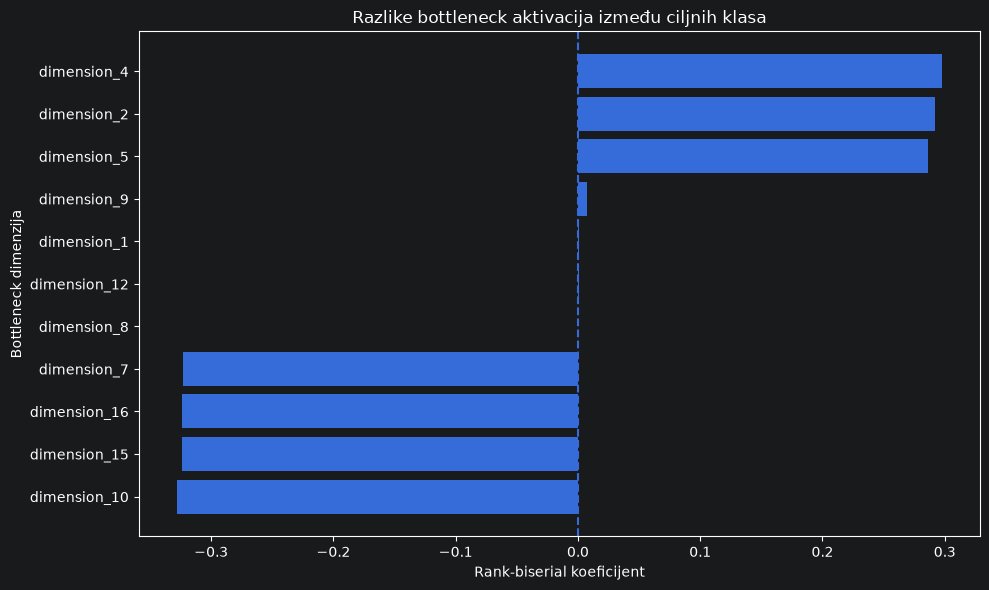

In [14]:
figure_path = (
    FIGURES_DIR
    / "bottleneck_class_effect_sizes.png"
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    active_class_comparison_df[
        "dimension"
    ],
    active_class_comparison_df[
        "rank_biserial"
    ]
)

plt.axvline(
    x=0,
    linestyle="--"
)

plt.xlabel(
    "Rank-biserial koeficijent"
)

plt.ylabel(
    "Bottleneck dimenzija"
)

plt.title(
    "Razlike bottleneck aktivacija između ciljnih klasa"
)

plt.tight_layout()

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Najizrazenije pozitivne efekte imaju dimenzije 2, 4, 5, to znaci da slucajno izabran primer sa readmisijom ima vecu aktivaciju ovih dimenzija od slucajno izabranog primera bez readmisije.<br>
Najizrazenije negativne vrednosti su dimenzije 7, 10, 15 i 16, njihove dimenzije imaju tendenciju ka vecim aktivacijama u klasi 0.<br>
Dimenzije 1, 8, 9 i 12 ne pokazuju statisticki znacajne razlike izmedju klasa, ostale dimenzije nisu testirane jer nisu imale varijaciju na test skupu.
Rezultati pokazuju da se bottleneck dimenzije ne ponasaju jednako u odnosu na ciljni ishod, da postoji statisticka povezanost ali ne i uzrocni uticaj.

---

## Provera povezanosti pojedinacnih aktivacija dimenzija sa izlazom.
Proveravamo logit, izlaz modela pre sigmoid funkcije, veci logit je veca predvidjena verovatnoca readmisije, i manji manja.<br>
Ako vece aktivacije prate vece logite, korelacija je pozitivna.<br>
Racunamo Spearman-ovu korelaciju izmedju aktivacija i logit-a, Spearman-ova korelacija proverava da li postoji monotona veza, kada jedna vrednost raste, da li i druga raste ili opada?

In [15]:
dimension_logit_results = []

for dimension_index, dimension_name in enumerate(
    dimension_names
):
    values = bottleneck[
        :,
        dimension_index
    ]

    active_on_test = np.any(
        values > 0
    )

    if active_on_test:
        correlation, p_value = spearmanr(
            values,
            test_logits
        )
    else:
        correlation = np.nan
        p_value = np.nan

    dimension_logit_results.append({
        "dimension": dimension_name,
        "active_on_test": active_on_test,
        "spearman_with_logit": correlation,
        "p_value": p_value
    })

In [16]:
dimension_logit_df = pd.DataFrame(
    dimension_logit_results
)

Dodajemo korigovane p vrednosti, apsolutnu korelaciju radi sortiranja, i statisticku znacajnost.

In [17]:
dimension_logit_df[
    "adjusted_p_value"
] = benjamini_hochberg_correction(
    dimension_logit_df["p_value"]
)
dimension_logit_df[
    "absolute_spearman"
] = dimension_logit_df[
    "spearman_with_logit"
].abs()
dimension_logit_df[
    "statistically_significant"
] = (
    dimension_logit_df[
        "adjusted_p_value"
    ] < 0.05
)

In [18]:
def determine_logit_direction(row):

    if not row["active_on_test"]:
        return "nije testirano"

    correlation = row[
        "spearman_with_logit"
    ]

    if (
        not row["statistically_significant"]
        or abs(correlation) < 0.05
    ):
        return "bez značajne povezanosti"

    if correlation > 0:
        return "pozitivna povezanost sa logitom"

    return "negativna povezanost sa logitom"


dimension_logit_df[
    "logit_direction"
] = dimension_logit_df.apply(
    determine_logit_direction,
    axis=1
)

In [19]:
dimension_logit_df = (
    dimension_logit_df
    .sort_values(
        by="absolute_spearman",
        ascending=False
    )
    .reset_index(drop=True)
)

In [20]:
dimension_logit_table_path = (
    TABLES_DIR
    / "bottleneck_dimension_logit_correlation.csv"
)

dimension_logit_df.to_csv(
    dimension_logit_table_path,
    index=False
)

dimension_logit_df.round(6)

,dimension,active_on_test,spearman_with_logit,p_value,adjusted_p_value,absolute_spearman,statistically_significant,logit_direction
0,dimension_10,True,-0.992222,0.00000,0.00000,0.992222,True,negativna povezanost sa logitom
1,dimension_16,True,-0.989814,0.00000,0.00000,0.989814,True,negativna povezanost sa logitom
2,dimension_7,True,-0.989079,0.00000,0.00000,0.989079,True,negativna povezanost sa logitom
3,dimension_15,True,-0.984390,0.00000,0.00000,0.984390,True,negativna povezanost sa logitom
4,dimension_4,True,0.867316,0.00000,0.00000,0.867316,True,pozitivna povezanost sa logitom
5,dimension_2,True,0.857479,0.00000,0.00000,0.857479,True,pozitivna povezanost sa logitom
6,dimension_5,True,0.841841,0.00000,0.00000,0.841841,True,pozitivna povezanost sa logitom
7,dimension_8,True,0.191104,0.00000,0.00000,0.191104,True,pozitivna povezanost sa logitom
8,dimension_9,True,0.154209,0.00000,0.00000,0.154209,True,pozitivna povezanost sa logitom
9,dimension_12,True,0.087381,0.00000,0.00000,0.087381,True,pozitivna povezanost sa logitom


Najvece negativne Spearman-ove korelacije imaju dimenzije 7, 10, 15 i 16, sto ukazuje na monotonu vezu u suprotnom smeru, veca aktivacija -> nizi logit modela -> manja verovatnoca readmisije.<br>
Najizrazenije pozitivne korelacije imaju 2, 4 i 5, veca aktivacija -> visi logit -> veca verovatnoca readmisije.<br>
Konacni logit zavisi od svih dimenzija zajedno, dimenzije mogu biti i medjusobno povezane, te Spearman-ova korelacije pojedinacne dimenzije sa logit-om ne predstavlja njen potpuni doprinos.

---

## Provera tezina izlaznog sloja i direktni doprinosi bottleneck dimenzija

Analiziramo tezine poslednjeg linearnog sloja modela. Izlazni logit se dobija kao zbir proizvoda bottleneck aktivacija i njihovih odgovarajucih izlaznih tezina uz dodavanje bias vrednosti.<br>


In [21]:
model_state_dict = torch.load(
    MODEL_DIR / "optimized_mlp_model.pt",
    map_location="cpu",
    weights_only=True
)

model_state_dict.keys()

odict_keys(['fc1.weight', 'fc1.bias', 'fc2.weight', 'fc2.bias', 'bottleneck.weight', 'bottleneck.bias', 'output.weight', 'output.bias'])

In [22]:
output_weights = (
    model_state_dict[
        "output.weight"
    ]
    .detach()
    .cpu()
    .numpy()
    .ravel()
)

output_bias = (
    model_state_dict[
        "output.bias"
    ]
    .detach()
    .cpu()
    .numpy()
    .item()
)

print(
    "Oblik izlaznih težina:",
    output_weights.shape
)

print(
    "Izlazni bias:",
    output_bias
)

Oblik izlaznih težina: (16,)
Izlazni bias: 0.1784990280866623


In [23]:
output_contributions = (
    bottleneck
    * output_weights
)

print(
    "Oblik matrice doprinosa:",
    output_contributions.shape
)

Oblik matrice doprinosa: (19868, 16)


mean_absolute_contribution pokazuje prosecnu velicinu doprinosa bez obzira na znak, koliko je veliki doprinos dimenzije.

In [24]:
dimension_contribution_df = pd.DataFrame({
    "dimension": dimension_names,

    "output_weight": output_weights,

    "mean_activation": (
        bottleneck.mean(axis=0)
    ),

    "active_fraction": (
        (bottleneck > 0).mean(axis=0)
    ),

    "mean_contribution": (
        output_contributions.mean(axis=0)
    ),

    "mean_absolute_contribution": (
        np.abs(
            output_contributions
        ).mean(axis=0)
    ),

    "contribution_std": (
        output_contributions.std(axis=0)
    )
})

In [25]:
def determine_output_direction(row):

    if row["active_fraction"] == 0:
        return "neaktivna na test skupu"

    if row["output_weight"] > 0:
        return "direktno povećava logit"

    if row["output_weight"] < 0:
        return "direktno smanjuje logit"

    return "nema direktan doprinos"


dimension_contribution_df[
    "output_direction"
] = dimension_contribution_df.apply(
    determine_output_direction,
    axis=1
)

In [26]:
dimension_contribution_df = (
    dimension_contribution_df
    .sort_values(
        by="mean_absolute_contribution",
        ascending=False
    )
    .reset_index(drop=True)
)

dimension_contribution_table_path = (
    TABLES_DIR
    / "bottleneck_dimension_output_contributions.csv"
)

dimension_contribution_df.to_csv(
    dimension_contribution_table_path,
    index=False
)

dimension_contribution_df.round(6)

,dimension,output_weight,mean_activation,active_fraction,mean_contribution,mean_absolute_contribution,contribution_std,output_direction
0,dimension_16,-0.222144,1.642533,0.731780,-0.364879,0.364879,0.397885,direktno smanjuje logit
1,dimension_10,-0.071295,0.793503,0.752114,-0.056572,0.056572,0.058405,direktno smanjuje logit
2,dimension_7,-0.075541,0.742075,0.723777,-0.056057,0.056057,0.058073,direktno smanjuje logit
3,dimension_4,0.181099,0.283722,0.372207,0.051382,0.051382,0.111393,direktno povećava logit
4,dimension_5,0.145471,0.318923,0.338132,0.046394,0.046394,0.108233,direktno povećava logit
5,dimension_2,0.077480,0.140549,0.358315,0.010890,0.010890,0.022514,direktno povećava logit
6,dimension_15,-0.017194,0.235284,0.728458,-0.004045,0.004045,0.003472,direktno smanjuje logit
7,dimension_1,-0.104788,0.002338,0.001258,-0.000245,0.000245,0.013344,direktno smanjuje logit
8,dimension_12,-0.105538,0.001478,0.019479,-0.000156,0.000156,0.007656,direktno smanjuje logit
9,dimension_8,0.014086,0.010574,0.199718,0.000149,0.000149,0.000500,direktno povećava logit


Najvazniji rezultat uocavamo kod dimenzije 16, aktivna je kod skoro 73.18% test primera, ima najvecu prosecnu aktivaciju, ima negativnu izlaznu tezinu, njene aktivacije smanjuju logit. Znacajne negativne dimenzije su i 10 i 7, dok su najvaznije pozitivne dimenzije 2, 4, 5. Za dimenziju 15 smo prethodno dobili snaznu negativnu Spearman-ovu korelaciju sa logit-om i vecu aktivaciju kod primera bez readmisije ali uocavamo da je njena izlazna tezina jako mala te je njen stvarni direktni doprinus logit-u mali.<br>
mean absolute contribution i mean contribution su jednake jer ReLU negativne vrednosti pretvara u 0.<br>
Smerovi prethondih analiza su potvrdjeni:<br>
dimenzije 2, 4 i 5 su bile vece kod readmisije i pozitivno povezane sa logit-om, sada imaju pozitivne tezine i direktno povecavaju logit.<br>
dimenzije 7, 10 i 16 su bile vece bez readmisije i negativno povezane sa logit-on, sada imaju negativne tezine i direktno smanjuju logit.<br>
dimenzija 15 ima negativan doprinos ali je on mnogo manji nego sto bi se zakljucilo.

Grafikon direktnih doprinosa.

In [27]:
active_contribution_df = (
    dimension_contribution_df[
        dimension_contribution_df[
            "active_fraction"
        ] > 0
    ]
    .sort_values(
        by="mean_contribution"
    )
)

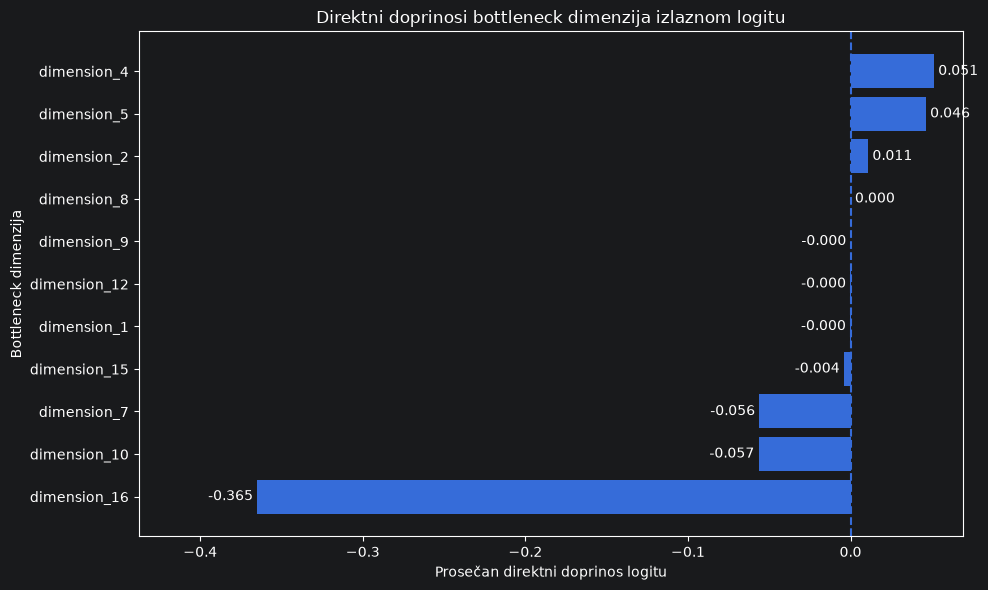

In [28]:
figure_path = (
    FIGURES_DIR
    / "bottleneck_mean_output_contributions.png"
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    active_contribution_df[
        "dimension"
    ],
    active_contribution_df[
        "mean_contribution"
    ]
)

plt.axvline(
    x=0,
    linestyle="--"
)

plt.xlabel(
    "Prosečan direktni doprinos logitu"
)

plt.ylabel(
    "Bottleneck dimenzija"
)

plt.title(
    "Direktni doprinosi bottleneck "
    "dimenzija izlaznom logitu"
)

plt.bar_label(
    bars,
    fmt="%.3f",
    padding=3
)

minimum_contribution = (
    active_contribution_df[
        "mean_contribution"
    ].min()
)

maximum_contribution = (
    active_contribution_df[
        "mean_contribution"
    ].max()
)

plt.xlim(
    minimum_contribution * 1.20,
    maximum_contribution * 1.35
)

plt.tight_layout()

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

---

## Povezivanje bottleneck dimenzija sa ulaznim karakteristikama pacijenata.

In [29]:
with np.load(
    representations_path
) as saved_data:

    input_representations = saved_data[
        "input"
    ]

In [30]:
feature_names_path = (
    MODELING_DATA_DIR
    / "target_diag_feature_names.csv"
)

feature_names = (
    pd.read_csv(
        feature_names_path
    )["feature_name"]
    .tolist()
)

In [31]:
print(
    "Oblik ulaznih reprezentacija:",
    input_representations.shape
)

print(
    "Broj naziva karakteristika:",
    len(feature_names)
)

print(
    "Broj redova odgovara bottleneck-u:",
    input_representations.shape[0]
    == bottleneck.shape[0]
)

print(
    "Broj kolona odgovara nazivima:",
    input_representations.shape[1]
    == len(feature_names)
)

Oblik ulaznih reprezentacija: (19868, 168)
Broj naziva karakteristika: 168
Broj redova odgovara bottleneck-u: True
Broj kolona odgovara nazivima: True


In [32]:
for feature_index, feature_name in enumerate(
    feature_names[:20]
):
    print(
        feature_index,
        feature_name
    )

0 num__num_lab_procedures
1 num__num_medications
2 num__num_procedures
3 num__number_diagnoses
4 num__number_emergency
5 num__number_inpatient
6 num__number_outpatient
7 num__time_in_hospital
8 onehot__race_AfricanAmerican
9 onehot__race_Asian
10 onehot__race_Caucasian
11 onehot__race_Hispanic
12 onehot__race_Missing
13 onehot__race_Other
14 onehot__gender_Female
15 onehot__gender_Male
16 onehot__age_[0-10)
17 onehot__age_[10-20)
18 onehot__age_[20-30)
19 onehot__age_[30-40)


Racunamo Spearman-ovu korelaciju bottleneck dimenzije sa svakom ulaznom karakteristikom.

In [33]:
feature_variation_mask = (
    np.nanstd(
        input_representations,
        axis=0
    ) > 0
)

dimension_variation_mask = (
    np.nanstd(
        bottleneck,
        axis=0
    ) > 0
)

print(
    "Broj ulaznih karakteristika sa varijacijom:",
    feature_variation_mask.sum()
)

print(
    "Broj aktivnih bottleneck dimenzija:",
    dimension_variation_mask.sum()
)

print(
    "Broj neaktivnih bottleneck dimenzija:",
    (~dimension_variation_mask).sum()
)

Broj ulaznih karakteristika sa varijacijom: 158
Broj aktivnih bottleneck dimenzija: 11
Broj neaktivnih bottleneck dimenzija: 5


Ova petlja prolazi za svaku dimenziju sve karakteristike i upisuje korelacije.

In [34]:
feature_dimension_results = []

for dimension_index, dimension_name in enumerate(
    dimension_names
):
    dimension_values = bottleneck[
        :,
        dimension_index
    ]

    dimension_has_variation = (
        dimension_variation_mask[
            dimension_index
        ]
    )

    for feature_index, feature_name in enumerate(
        feature_names
    ):
        feature_values = input_representations[
            :,
            feature_index
        ]

        feature_has_variation = (
            feature_variation_mask[
                feature_index
            ]
        )

        tested = (
            dimension_has_variation
            and feature_has_variation
        )

        if tested:
            correlation, p_value = spearmanr(
                feature_values,
                dimension_values,
                nan_policy="omit"
            )
        else:
            correlation = np.nan
            p_value = np.nan

        feature_dimension_results.append({
            "dimension": dimension_name,
            "feature": feature_name,
            "dimension_active": bool(
                dimension_has_variation
            ),
            "feature_has_variation": bool(
                feature_has_variation
            ),
            "tested": bool(tested),
            "spearman_correlation": correlation,
            "p_value": p_value
        })

In [35]:
feature_dimension_df = pd.DataFrame(
    feature_dimension_results
)

print(
    "Broj redova u tabeli:",
    len(feature_dimension_df)
)

print(
    "Broj izvršenih testova:",
    feature_dimension_df[
        "tested"
    ].sum()
)

feature_dimension_df.head()

Broj redova u tabeli: 2688
Broj izvršenih testova: 1738


,dimension,feature,dimension_active,feature_has_variation,tested,spearman_correlation,p_value
0,dimension_1,num__num_lab_procedures,True,True,True,-0.009666,0.173090
1,dimension_1,num__num_medications,True,True,True,-0.017667,0.012762
2,dimension_1,num__num_procedures,True,True,True,0.008072,0.255246
3,dimension_1,num__number_diagnoses,True,True,True,0.007320,0.302165
4,dimension_1,num__number_emergency,True,True,True,0.000839,0.905897


Korigujemo p vrednosti.

In [36]:
feature_dimension_df[
    "adjusted_p_value"
] = benjamini_hochberg_correction(
    feature_dimension_df[
        "p_value"
    ]
)

Dodajemo apsolutnu korelaciju i statisticku znacajnost.

In [37]:
feature_dimension_df[
    "absolute_spearman"
] = feature_dimension_df[
    "spearman_correlation"
].abs()

feature_dimension_df[
    "statistically_significant"
] = (
    feature_dimension_df[
        "adjusted_p_value"
    ] < 0.05
)

Opis smera.

In [38]:
def determine_feature_relationship(row):

    if not row["tested"]:
        return "nije testirano"

    correlation = row[
        "spearman_correlation"
    ]

    if not row["statistically_significant"]:
        return "nije statistički značajna"

    if abs(correlation) < 0.05:
        return (
            "statistički značajna, "
            "ali praktično zanemarljiva"
        )

    if correlation > 0:
        return "pozitivna povezanost"

    return "negativna povezanost"


feature_dimension_df[
    "relationship_direction"
] = feature_dimension_df.apply(
    determine_feature_relationship,
    axis=1
)

In [39]:
feature_dimension_df = (
    feature_dimension_df
    .sort_values(
        by="absolute_spearman",
        ascending=False,
        na_position="last"
    )
    .reset_index(drop=True)
)

feature_dimension_table_path = (
    TABLES_DIR
    / "bottleneck_input_feature_correlations.csv"
)

feature_dimension_df.to_csv(
    feature_dimension_table_path,
    index=False
)

feature_dimension_df.head(20).round(6)

,dimension,feature,dimension_active,feature_has_variation,tested,spearman_correlation,p_value,adjusted_p_value,absolute_spearman,statistically_significant,relationship_direction
0,dimension_5,num__number_inpatient,True,True,True,0.634186,0.0,0.0,0.634186,True,pozitivna povezanost
1,dimension_2,num__number_inpatient,True,True,True,0.628669,0.0,0.0,0.628669,True,pozitivna povezanost
2,dimension_4,num__number_inpatient,True,True,True,0.628408,0.0,0.0,0.628408,True,pozitivna povezanost
3,dimension_10,num__number_inpatient,True,True,True,-0.589284,0.0,0.0,0.589284,True,negativna povezanost
4,dimension_15,num__number_inpatient,True,True,True,-0.587774,0.0,0.0,0.587774,True,negativna povezanost
5,dimension_16,num__number_inpatient,True,True,True,-0.584858,0.0,0.0,0.584858,True,negativna povezanost
6,dimension_7,num__number_inpatient,True,True,True,-0.582451,0.0,0.0,0.582451,True,negativna povezanost
7,dimension_16,diag_target__diag_3,True,True,True,-0.518900,0.0,0.0,0.518900,True,negativna povezanost
8,dimension_10,diag_target__diag_3,True,True,True,-0.516811,0.0,0.0,0.516811,True,negativna povezanost
9,dimension_7,diag_target__diag_3,True,True,True,-0.515188,0.0,0.0,0.515188,True,negativna povezanost


Izdvajanje 10 najjacih karakteristika za svaku dimenziju.

In [40]:
tested_feature_dimension_df = (
    feature_dimension_df[
        feature_dimension_df[
            "tested"
        ]
    ]
    .copy()
)

top_features_by_dimension_df = (
    tested_feature_dimension_df
    .sort_values(
        by=[
            "dimension",
            "absolute_spearman"
        ],
        ascending=[
            True,
            False
        ]
    )
    .groupby(
        "dimension",
        group_keys=False
    )
    .head(10)
    .reset_index(drop=True)
)

top_features_by_dimension_df.round(6)

,dimension,feature,dimension_active,feature_has_variation,tested,spearman_correlation,p_value,adjusted_p_value,absolute_spearman,statistically_significant,relationship_direction
0,dimension_1,diag_target__diag_2,True,True,True,0.061163,0.000000,0.000000,0.061163,True,pozitivna povezanost
1,dimension_1,onehot__medical_specialty_Surgery-Thoracic,True,True,True,0.049039,0.000000,0.000000,0.049039,True,"statistički značajna, ali praktično zanemarljiva"
2,dimension_1,onehot__discharge_disposition_id_8,True,True,True,0.038742,0.000000,0.000000,0.038742,True,"statistički značajna, ali praktično zanemarljiva"
3,dimension_1,onehot__medical_specialty_Oncology,True,True,True,0.020611,0.003668,0.007690,0.020611,True,"statistički značajna, ali praktično zanemarljiva"
4,dimension_1,onehot__insulin_No,True,True,True,0.018344,0.009717,0.019546,0.018344,True,"statistički značajna, ali praktično zanemarljiva"
...,...,...,...,...,...,...,...,...,...,...,...
105,dimension_9,num__num_lab_procedures,True,True,True,0.095855,0.000000,0.000000,0.095855,True,pozitivna povezanost
106,dimension_9,onehot__age_[80-90),True,True,True,0.087925,0.000000,0.000000,0.087925,True,pozitivna povezanost
107,dimension_9,onehot__admission_source_id_1,True,True,True,-0.079271,0.000000,0.000000,0.079271,True,negativna povezanost
108,dimension_9,onehot__admission_type_id_3,True,True,True,-0.078735,0.000000,0.000000,0.078735,True,negativna povezanost


In [41]:
top_features_table_path = (
    TABLES_DIR
    / "bottleneck_top_input_features.csv"
)

top_features_by_dimension_df.to_csv(
    top_features_table_path,
    index=False
)

Dimenzije 2, 4 i 5 predstavljaju slican obrazac: najjaca povezanost je sa num__number_inpatient, sto znaci da veci broj prethodnih poseta prati vecu aktivaciju ovih dimenzija. Njihove aktivacije takodje rastu uz vise vrednosti target kodiranih dijagnoza (diag_target__diag_3, diag_target__diag_2, diag_target__diag_1), veci broj hitnih poseta (number_emergency), duzi boravak u bolnici (time_in_hospital), veci broj dijagnoza (number_diagnoses), veci broj lekova (num_medications) i discharge_disposition_id_3 (discharged/transferred to SNF). Negativno su povezane sa onehot__discharge_disposition_id_1 (dsicharged to home). Posto smo utvrdili da ove dimenzije povecavaju logit, mozemo reci da su ovo karakteristike pacijenata sa visim predvidjenim skorom readmisije.<br>
Dimenzije 7, 10, 15 i 16 predstavljaju obrnuti obrazac, njihove aktivacije opadaju uz ove karakteristike, a pozitivno su povezane sa onehot__discharge_disposition_id_1.<br>
Dakle, dimenzije 2, 4 i 5 i dimenzije 7, 10, 15 i 16 imaju prakticno iste najvaznije karakteristike ali sa suprotnim znacima. Povezanost sa slicnim (istim) ulaznim karakteristikama ali u suprotnim smerovima ukazuje na preklapanje i mogucu redundantnost latentnih karakteristika.